# 013 网络可视化：题目要求

**需要完成：** 冻结预训练 SqueezeNet；计算并展示显著图；用归一化输入梯度生成目标类别欺骗图并断言成功；完成带 L2、抖动和模糊的类别可视化。

**实验范围与验收：** 使用课程 ImageNet 验证样例。网络参数不训练；实际优化和求导对象为输入图像。

**阅读顺序：** 先阅读原题和代码块前的中文解析，再检查实际输出与问题记录；若本题包含方法二，它紧随对应方法一，使用独立状态。方法一不得依赖方法二才能运行。

**课程参考：** [CS231n 课程资料](https://cs231n.github.io/)。本题的实现、检查和实验结果按下文顺序记录。

## 读代码前先看模型：输入梯度与显著图

区分训练模型参数与对输入求导。这里只问哪个像素的微小变化最能改变指定类别得分，因此把输入作为求导变量。

![输入梯度与显著图的数据流](../assets/model_flow/013_NetworkVisualization_PyTorch.svg)

**从定义推到实现。**

$$
s_y(X+\Delta)\approx s_y(X)+\langle\nabla_X s_y,\Delta\rangle
$$

一阶近似中的梯度给出每个方向的局部敏感性。对 RGB 三个梯度取绝对值的最大值得到二维图。欺骗图则沿目标类梯度上升，直到预测类别改变。

**库在这里解决什么问题？** gather 按标签取每幅图的目标 logit；autograd.grad 返回对输入的梯度；amax(dim=1) 消去颜色轴，保留 batch 轴。

| 本题导入的模块 | 在这份实验中的用途 |
|---|---|
| `PIL` | 把 JPEG 等文件解码成像素，并在 PIL 图像与数组或张量之间传递图像。 |
| `cs231n.data_utils` | 处理该作业的数据、特征或显示输入，使主实验能直接使用约定的数组格式。 |
| `cs231n.image_utils` | 处理该作业的数据、特征或显示输入，使主实验能直接使用约定的数组格式。 |
| `matplotlib.pyplot` | 把像素、损失或准确率转换为可读图像，绘图单元只读取已有结果。 |
| `numpy` | 把一批样本作为数组处理。矩阵乘法合并样本计算，广播让偏置或均值沿样本轴复用。 |
| `os` | 读取运行环境或处理路径，连接实验代码和本机文件系统。 |
| `pathlib` | 构造数据与结果的文件路径，使当前作业从约定目录读取资源。 |
| `random` | 控制 Python 自己的随机抽样，例如图像平移。它与 NumPy、PyTorch 的随机状态分别管理。 |
| `scipy.ndimage.filters` | 提供图像滤波等数值算子，用于局部特征聚合或平滑图像。 |
| `study_runtime` | 解析共享数据路径、读取本机资源或保存本题结果，避免各题重复创建数据副本。 |
| `sys` | 设置本作业的模块搜索路径，使同名 cs231n 包来自当前 assignment。 |
| `threadpoolctl` | 限制数值库的并行线程，避免小矩阵运算把更多时间花在线程调度上。 |
| `torch` | 存储带设备、类型和梯度信息的张量；训练时构建计算图，求导后由优化器更新参数。 |
| `torch.autograd` | 存储带设备、类型和梯度信息的张量；训练时构建计算图，求导后由优化器更新参数。 |
| `torchvision` | 读取带标签的图像数据、执行一致的图像变换，或加载本题指定的预训练视觉网络。 |
| `torchvision.transforms` | 读取带标签的图像数据、执行一致的图像变换，或加载本题指定的预训练视觉网络。 |

**用一个小例子检查理解。** 一个像素对目标得分的 RGB 梯度为 [−0.1,0.6,−0.4]，图上的显著值是 0.6。绝对值表示敏感程度，丢掉了“增加还是降低得分”的方向信息。

# 网络可视化(PyTorch)
在这个笔记本中，我们将探索使用*图像梯度*生成新的图像。
当训练一个模型时，我们定义一个损失函数来衡量我们当前对模型表现的不满;然后，我们使用反向传播来计算相对于模型参数的损耗梯度，并对模型参数进行梯度下降以最小化损耗。
这里我们将做一些稍微不同的事情。我们将从一个卷积神经网络模型开始，该模型经过预处理，用于在ImageNet数据集上执行图像分类。我们将使用这个模型来定义一个损失函数，量化我们当前对图像的不满意程度，然后使用反向传播来计算这个损失相对于图像像素的梯度。我们将保持模型不变，并对图像进行梯度下降*，以合成一个新的图像，使损失最小化。
在本笔记本中，我们将探讨三种技术的图像生成:
1. **显著性映射**:显著性映射是一种快速判断图像的哪一部分影响了网络的分类决策的方法。
2. **欺骗图像**:我们可以扰乱一个输入图像，使它看起来对人类是一样的，但会被预先训练好的网络错误分类。
3. **类可视化**:我们可以合成一个图像来最大化特定类的分类分数;这可以给我们一些感觉，网络正在寻找什么，当它分类的图像类。

本笔记本使用**PyTorch**;我们提供了另一个笔记本，它探索了TensorFlow中相同的概念。你只需要完成这两个笔记本中的一个。

**本段解析**

固定 NumPy 与 Python 随机种子为 231，读取共享数据配置，并限制 BLAS 线程数量。这样既能运行验证初始化和抽样，也能避免小矩阵运算中线程调度开销；原始数据文件保持不变。

**第 1 块：顺着变量读**

本块实际导入：`os`、`sys`、`random`、`pathlib.Path`、`study_runtime.data_path`、`numpy`、`threadpoolctl.threadpool_limits`。各模块在本题中的职责见开头的库说明。

In [1]:
# 固定实验起点；读取共享数据路径；限制 BLAS 线程，避免多线程调度开销。
import os, sys, random
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
from study_runtime import data_path
import numpy as np
from threadpoolctl import threadpool_limits
_blas_limit = threadpool_limits(limits=4)
np.random.seed(231)
random.seed(231)


**第 2 块｜准备输入梯度工具**

导入 PyTorch、Pillow、图像变换和高斯滤波工具，固定随机种子。此题模型权重冻结，优化对象或求导对象是输入图片，不是重新训练分类网络。

本块实际导入：`torch`、`torch.autograd.Variable`、`torchvision`、`torchvision.transforms`、`random`、`numpy`、`scipy.ndimage.filters.gaussian_filter1d`、`matplotlib.pyplot`、`cs231n.image_utils.SQUEEZENET_MEAN`、`cs231n.image_utils.SQUEEZENET_STD`、`PIL.Image`。各模块在本题中的职责见开头的库说明。

In [2]:
import torch
torch.manual_seed(231)
torch.set_num_threads(4)
from torch.autograd import Variable
import torchvision
import torchvision.transforms as T
import random

import numpy as np
from scipy.ndimage.filters import gaussian_filter1d
import matplotlib.pyplot as plt
from cs231n.image_utils import SQUEEZENET_MEAN, SQUEEZENET_STD
from PIL import Image

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # 设置地块的默认大小
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

C:\Users\20240\AppData\Local\Temp\ipykernel_57192\3311868175.py:10: DeprecationWarning: Please import `gaussian_filter1d` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.ndimage.filters import gaussian_filter1d


### 辅助功能
我们的预训练模型是在经过预处理的图像上进行训练的，这些图像是通过减去每一种颜色的平均值并除以每一种颜色的标准差得到的。我们定义了一些辅助函数来执行和取消这个预处理。你不需要在这里做任何事。

**第 3 块｜定义图像预处理与还原**

定义预处理、反预处理、重缩放和模糊函数。输入 PIL 图像先按短边缩放，再转 CHW 浮点张量并按 SqueezeNet 均值方差标准化；反处理还原可显示的像素，显示缩放不应混入优化公式。

此处定义 `preprocess(img, size=224)`。函数体在调用时执行。

此处定义 `deprocess(img, should_rescale=True)`。函数体在调用时执行。

此处定义 `rescale(x)`。函数体在调用时执行。

- `T.Normalize(mean=SQUEEZENET_MEAN.tolist(), std=SQUEEZENET_STD.tolist())`：对每个通道减均值、除标准差，使输入尺度与模型约定一致。

本块产出的变量接着用于：`deprocess` → 第 12 块，`preprocess` → 第 12 块。

In [3]:
def preprocess(img, size=224):
    transform = T.Compose([
        T.Resize(size),
        T.ToTensor(),
        T.Normalize(mean=SQUEEZENET_MEAN.tolist(),
                    std=SQUEEZENET_STD.tolist()),
        T.Lambda(lambda x: x[None]),
    ])
    return transform(img)

def deprocess(img, should_rescale=True):
    transform = T.Compose([
        T.Lambda(lambda x: x[0]),
        T.Normalize(mean=[0, 0, 0], std=(1.0 / SQUEEZENET_STD).tolist()),
        T.Normalize(mean=(-SQUEEZENET_MEAN).tolist(), std=[1, 1, 1]),
        T.Lambda(rescale) if should_rescale else T.Lambda(lambda x: x),
        T.ToPILImage(),
    ])
    return transform(img)

def rescale(x):
    low, high = x.min(), x.max()
    x_rescaled = (x - low) / (high - low)
    return x_rescaled
    
def blur_image(X, sigma=1):
    X_np = X.cpu().clone().numpy()
    X_np = gaussian_filter1d(X_np, sigma, axis=2)
    X_np = gaussian_filter1d(X_np, sigma, axis=3)
    X.copy_(torch.Tensor(X_np).type_as(X))
    return X

# 预训练模型
对于我们所有的图像生成实验，我们将从一个卷积神经网络开始，该网络经过预先训练在ImageNet上执行图像分类。我们可以使用任何模型在这里，但为了这个任务的目的，我们将使用SqueezeNet[1]，它实现的精度可与AlexNet相比，但大大减少了参数计数和计算复杂性。
使用SqueezeNet而不是AlexNet或VGG或ResNet意味着我们可以很容易地在CPU上执行所有图像生成实验。

[1] Iandola et al, "SqueezeNet: AlexNet水平精度,参数减少50x, 模型大小< 0.5MB", arXiv 2016

**第 4 块｜冻结预训练权重**

从共享 torch 缓存加载官方 SqueezeNet 1.1 ImageNet 权重，关闭所有参数梯度。冻结参数可减少反向开销，但输入图像仍可设置 requires_grad=True；评估时使用 eval 模式。

本块产出的变量接着用于：`model` → 第 8 块。

In [4]:
# 下载并加载预装的SqueezeNet模型.
model = torchvision.models.squeezenet1_1(weights=torchvision.models.SqueezeNet1_1_Weights.IMAGENET1K_V1)

# 我们不想训练模型,所以告诉PyTorch不要计算梯度
# 关于模型参数。
for param in model.parameters():
    param.requires_grad = False

## 加载一些ImageNet图像
我们提供了一些来自ImageNet ILSVRC 2012分类数据集验证集的示例图像。要下载这些图像，请打开'cs231n/datasets/'并运行'get_imagenet_val.sh'。
由于它们来自验证集，我们的预训练模型在训练期间没有看到这些图像。
运行以下单元格来可视化这些图像，以及它们的ground-truth标签。

**第 5 块｜显示待分析的原图**

读取课程的 ImageNet 验证样例包，取五张图及其类别名称并显示。该文件包含课程提供的对象形式标签映射，因此仅对这个已核验资源允许对象加载。

本块实际导入：`cs231n.data_utils.load_imagenet_val`。各模块在本题中的职责见开头的库说明。

本块产出的变量接着用于：`X` → 第 8 块，`class_names` → 第 12 块，`y` → 第 8 块。

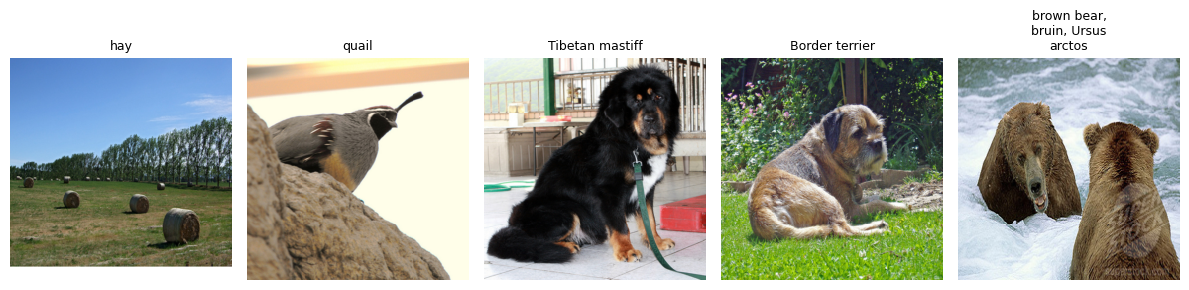

In [5]:
from cs231n.data_utils import load_imagenet_val
X, y, class_names = load_imagenet_val(num=5)

plt.figure(figsize=(12, 6))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X[i])
    plt.title(__import__('textwrap').fill(class_names[y[i]], width=16), fontsize=9)
    plt.axis('off')
plt.gcf().tight_layout()

# 显著地图
使用这个预训练的模型，我们将计算类显著性映射，如[2]的3.1节所述。
一个**显著性图**告诉我们图像中的每个像素对该图像的分类分数的影响程度。为了计算它，我们计算了对应于正确类(一个标量)的非标准化分数相对于图像像素的梯度。如果图像有形状' (3,H, W) '，那么这个梯度也将有形状' (3,H, W) ';对于图像中的每一个像素，这个梯度告诉我们，如果像素变化很小，分类分数会改变多少。为了计算显著性图，我们取梯度的绝对值，然后取三个输入通道上的最大值;因此，最终的显著性映射具有形状' (H, W) '，并且所有条目都是非负的。

[2] Karen Simonyan, Andrea Vedaldi, and Andrew Zisserman. "深陷革命网络:视觉
图像分类模型和显著地图,ICLR讲习班,2014年.

### 为什么要用 gather？

网络给出 N×C 得分，但每张图的真实类别可以不同。把 N 个标签改为 N×1 后，gather 沿类别维为每行取出指定的一项。把这些目标分数加起来求导，就能在同一次反向传播中得到每幅图片的梯度。

**第 6 块｜按标签选择目标得分**

用小的随机得分矩阵演示 gather 按每行标签提取对应类别分数。输出每个样本的目标 logit，为显著图对正确类别求导的操作建立直观对应。

此处定义 `gather_example()`。函数体在调用时执行。

- `s.gather(1, y.view(-1, 1))`：按每行的标签从类别得分中选出目标元素。

In [6]:
# 使用集合从 PyTorch每行中选择一个条目的示例
def gather_example():
    N, C = 4, 5
    s = torch.randn(N, C)
    y = torch.LongTensor([1, 2, 1, 3])
    print(s)
    print(y)
    print(s.gather(1, y.view(-1, 1)).squeeze())
gather_example()

tensor([[ 0.8180, -1.5696, -1.1886,  0.2511, -0.3357],
        [-0.5814, -1.6366,  0.9369,  0.6021,  1.0473],
        [ 0.1898, -1.1258, -1.3756,  0.8381,  0.0498],
        [ 0.4673, -0.4327,  0.4179, -0.8454,  1.3618]])
tensor([1, 2, 1, 3])
tensor([-1.5696,  0.9369, -1.1258, -0.8454])


**第 7 块｜对目标分数求输入梯度**

把输入图像设为需要梯度，提取每张图真实类别的 logit 并反向传播。对输入梯度取绝对值，再沿 RGB 通道取最大值，得到每个像素的敏感度图；显著性表示局部敏感性，不等于因果解释。

此处定义 `compute_saliency_maps(X, y, model)`。函数体在调用时执行。

- `scores.backward(torch.ones_like(scores))`：沿已经构建的计算图反向传播损失，写入参数或输入的梯度。

- `scores.gather(1, y_var.view(-1, 1))`：按每行的标签从类别得分中选出目标元素。

本块产出的变量接着用于：`compute_saliency_maps` → 第 8 块。

In [7]:
def compute_saliency_maps(X, y, model):
    """输入 N 张标准化图像及 N 个类别索引。对每张图对应的真实类别得分求输入梯度，取 RGB 梯度绝对值的通道最大值。此实现最后使用 squeeze，单图时会去掉批次轴；方法二给出保留该轴的写法。"""
    # 确保模型处于“测试”模式
    model.eval()
    
    # 在变量中环绕输入分数
    X_var = Variable(X, requires_grad=True)
    y_var = Variable(y)
    saliency = None
    # 利用正确分类的score去计算输入图片的梯度。
    # 然后取梯度的绝对值，在3个通道上选择最大的那个值。
    scores=model(X_var)
    scores=scores.gather(1,y_var.view(-1,1)).squeeze()
    # 向量对向量求导
    tmp=scores.backward(torch.ones_like(scores))
    saliency=X_var.grad.data
    saliency,index=torch.max(saliency.abs(),dim=1)
    saliency=saliency.squeeze()
    return saliency

### 方法二：直接求输入梯度，保持批次维度

方法一通过 `Variable`、`backward` 和 `.grad` 读取显著图。我增加一个更短的实现：复制输入为独立叶张量，求目标 logits 的和，再用 `torch.autograd.grad` 直接取得输入梯度。返回值沿通道取最大绝对值，保持 `(N,H,W)`，不使用可能在 N=1 时删去批次维的无条件 `squeeze()`。

此方法不训练网络，也不覆盖原函数。输入张量及其 `.grad` 不被修改，函数结束时恢复网络原来的训练/评估模式。下面在同一五张图上逐元素比较两种实现，并专门检查单图批次。这里的收益是代码简化与接口边界更清楚，不声称改变了显著图算法或提高分类性能。

**第 8 块：顺着变量读**

此处定义 `saliency_maps_method2(images, labels, network)`。函数体在调用时执行。

- `network(query).gather(1, labels[:, None])`：按每行的标签从类别得分中选出目标元素。

- `images.detach()`：截断这一分支的反向传播，后续损失不会更新产生该张量的模型。

前序输入：`X` 来自第 5 块，`y` 来自第 5 块，`model` 来自第 4 块，`compute_saliency_maps` 来自第 7 块。

In [8]:
def saliency_maps_method2(images, labels, network):
    """直接返回输入梯度，不累积叶张量 .grad，保留 N=1 时的 batch 维。"""
    previous_mode = network.training
    try:
        network.eval()
        query = images.detach().clone().requires_grad_(True)
        with torch.enable_grad():
            target_scores = network(query).gather(1, labels[:, None]).sum()
            input_gradient, = torch.autograd.grad(target_scores, query)
        return input_gradient.abs().amax(dim=1)
    finally:
        network.train(previous_mode)

method2_images = torch.cat([preprocess(Image.fromarray(image)) for image in X], dim=0)
method2_labels = torch.as_tensor(y, dtype=torch.long)
method2_maps = saliency_maps_method2(method2_images, method2_labels, model)
reference_maps = compute_saliency_maps(method2_images, method2_labels, model)
torch.testing.assert_close(method2_maps, reference_maps, rtol=1e-6, atol=1e-7)
single_map = saliency_maps_method2(method2_images[:1], method2_labels[:1], model)
assert single_map.shape == (1, method2_images.shape[2], method2_images.shape[3])
assert method2_images.grad is None
print({'max_absolute_difference':(method2_maps-reference_maps).abs().max().item(),
       'single_image_shape':tuple(single_map.shape),'input_grad_not_accumulated':method2_images.grad is None})


{'max_absolute_difference': 0.0, 'single_image_shape': (1, 224, 224), 'input_grad_not_accumulated': True}


一旦你在上面的单元格中完成了实现，运行下面的代码，在来自ImageNet验证集的示例图像上可视化一些类显著性映射:

**第 9 块｜将显著图与原图对齐**

把五张原图预处理为一批，调用显著图函数并与原图并排展示。输出 shape 应为 (N,H,W)，颜色强度表示目标 logit 对该像素变化的敏感程度。

此处定义 `show_saliency_maps(X, y)`。函数体在调用时执行。

前序输入：`X` 来自第 5 块，`y` 来自第 5 块。

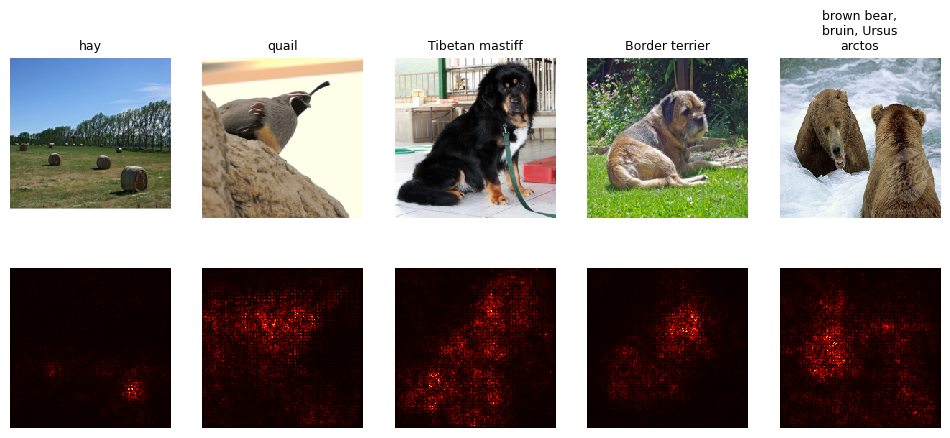

In [9]:
def show_saliency_maps(X, y):
    # 将X 和 Y从 numpy 数组转换为 火炬十进制
    X_tensor = torch.cat([preprocess(Image.fromarray(x)) for x in X], dim=0)
    y_tensor = torch.LongTensor(y)

    # 计算X 中图像的显著地图
    saliency = compute_saliency_maps(X_tensor, y_tensor, model)

    # 从 Torch Tensor 转换成 numpy 阵列并显示图像
    # 和显著的地图一起。
    saliency = saliency.numpy()
    N = X.shape[0]
    for i in range(N):
        plt.subplot(2, N, i + 1)
        plt.imshow(X[i])
        plt.axis('off')
        plt.title(__import__('textwrap').fill(class_names[y[i]], width=16), fontsize=9)
        plt.subplot(2, N, N + i + 1)
        plt.imshow(saliency[i], cmap=plt.cm.hot)
        plt.axis('off')
        plt.gcf().set_size_inches(12, 5)
    plt.show()

show_saliency_maps(X, y)

# 愚弄图片
我们还可以使用图像梯度来生成[3]中讨论的“欺骗图像”。给定一个图像和一个目标类，我们可以在图像上执行梯度**上升期**来最大化目标类，当网络将图像分类为目标类时停止。实现以下函数来生成欺骗图像。

[3] Szegedy等人,"神经网络的特异性",ICLR 2014

**第 10 块｜沿目标类梯度更新图片**

从原图副本开始，反复对目标类别得分做梯度上升，每次按梯度 L2 范数归一化。模型参数始终冻结，只更新图片；当 argmax 变为目标类时停止，并保留迭代次数。

此处定义 `make_fooling_image(X, target_y, model)`。函数体在调用时执行。

- `target_score.backward()`：沿已经构建的计算图反向传播损失，写入参数或输入的梯度。

- `model.zero_grad()`：清空上次更新遗留的梯度，为当前批次计算做准备。

本块产出的变量接着用于：`make_fooling_image` → 第 11 块。

In [10]:
def make_fooling_image(X, target_y, model):
    """复制一张输入图片，沿目标类别得分对像素的梯度上升，每次用梯度范数归一化方向。返回使模型预测为 target_y 的图片，模型权重不参与更新。"""
    # 初始化我们的愚弄图像到输入图像, 并把它包裹在一个变量中 。
    X_fooling = X.clone()
    X_fooling_var = Variable(X_fooling, requires_grad=True)
    
    learning_rate = 1
    scores=model(X_fooling_var)
    _,y_predit=scores.max(dim=1)
    iter=0
    while(y_predit!=target_y):
        iter += 1
        if(iter%10==0):
            print("Iteration: %d"% iter)
        # 选择最第一张图片，对应的目标得分
        target_score=scores[0,target_y]
        # 标量直接返回梯度
        target_score.backward()
        
        reg=X_fooling_var.grad/X_fooling_var.grad.norm()
        X_fooling.data+=learning_rate*reg
        # 清除缓存梯度
        X_fooling_var.grad.zero_()
        model.zero_grad()
        scores=model(X_fooling_var)
        _,y_predit=scores.max(dim=1)  
    print("Iteration Count: %d"% iter)
    return X_fooling

下面固定一幅图和目标类别，再运行梯度上升。只有重新前向后的最大得分类别确实等于目标，才算生成成功。

**第 11 块｜断言目标类别已达到**

选定样本和目标类别，生成欺骗图像后重新前向，断言预测已经变为目标类。断言检查实际攻击是否成功，不能仅因为图像生成过程没有报错就认为成功。

前序输入：`X` 来自第 5 块，`make_fooling_image` 来自第 10 块，`model` 来自第 4 块。

本块产出的变量接着用于：`X_fooling` → 第 12 块，`idx` → 第 12 块，`target_y` → 第 12 块。

In [11]:
idx = 0
target_y = 6

X_tensor = torch.cat([preprocess(Image.fromarray(x)) for x in X], dim=0)
X_fooling = make_fooling_image(X_tensor[idx:idx+1], target_y, model)

scores = model(Variable(X_fooling))
assert target_y == scores.data.max(1)[1][0].item(), 'The model is not fooled!'

Iteration Count: 9


把原图、更新后的图、像素差和放大后的像素差放在一起看。第四幅图只用于观察微弱扰动。

**第 12 块｜查看原图与扰动差异**

并排显示原图、欺骗图、差分及放大十倍差分。显示时的颜色缩放只帮助观察扰动，放大差分并不是实际送入网络的图像，也不代表攻击具有感知不可见性保证。

前序输入：`deprocess` 来自第 3 块，`X_fooling` 来自第 11 块，`X` 来自第 5 块，`idx` 来自第 11 块，`class_names` 来自第 5 块，`y` 来自第 5 块，`target_y` 来自第 11 块。

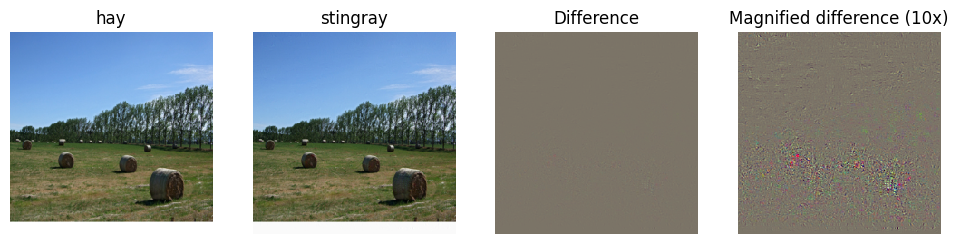

In [12]:
X_fooling_np = deprocess(X_fooling.clone())
X_fooling_np = np.asarray(X_fooling_np).astype(np.uint8)

plt.subplot(1, 4, 1)
plt.imshow(X[idx])
plt.title(class_names[y[idx]])
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(X_fooling_np)
plt.title(class_names[target_y])
plt.axis('off')

plt.subplot(1, 4, 3)
X_pre = preprocess(Image.fromarray(X[idx]))
diff = np.asarray(deprocess(X_fooling - X_pre, should_rescale=False))
plt.imshow(diff)
plt.title('Difference')
plt.axis('off')

plt.subplot(1, 4, 4)
diff = np.asarray(deprocess(10 * (X_fooling - X_pre), should_rescale=False))
plt.imshow(diff)
plt.title('Magnified difference (10x)')
plt.axis('off')

plt.gcf().set_size_inches(12, 5)
plt.show()

# 类可视化
通过从一个随机噪声图像开始，并对一个目标类执行梯度上升，我们可以生成一个网络将识别为目标类的图像。这个想法最初是在[2]中提出的;[3]扩展了这一思想，提出了几种正则化技术，可以提高生成的图像的质量。

Concretely, let $I$成为一个图像并让$y$成为目标班,让我们$s_y(I)$是一个进化网络给图像分配的分数$I$类别$y$; 注意这些是原始非正常的分数,而不是类概率。我们希望生成一个图像$I^*$达到高分的班级$y$通过解决问题

$$
I^* = \arg\max_I s_y(I) - R(I)
$$

where $R$是一个(可能隐含的)正则符(注意:$R(I)$:我们想要最小化此规范化术语 。我们可以使用梯度升起、 计算生成图像的梯度来解决优化问题。我们将使用( 明确) L2 规范化的形式 。

$$
R(I) = \lambda \|I\|_2^2
$$

**和**按照 [3] 的建议,通过定期模糊生成的图像来隐含规范化。我们可以通过在生成的图像上梯度上升来解决这个问题。

在下面的单元中,完成执行`create_class_visualization` function.

[2] Karen Simonyan, Andrea Vedaldi, and Andrew Zisserman. "深陷革命网络:视觉
图像分类模型和显著地图,ICLR讲习班,2014年.

[3] Yosinski等人,"通过深视界了解神经网络",ICML 2015深度学习讲习班

**第 13 块｜定义可逆的空间抖动**

jitter 沿宽高方向循环平移图像，保持尺寸不变。类别可视化中先随机平移再更新，之后用相反位移还原，缓解局部网格伪影。

此处定义 `jitter(X, ox, oy)`。函数体在调用时执行。

In [13]:
def jitter(X, ox, oy):
    """将 NCHW 张量按 ox、oy 在宽高方向循环平移，输出形状不变。优化后施加相反位移，可将图像放回原坐标系。"""
    if ox != 0:
        left = X[:, :, :, :-ox]
        right = X[:, :, :, -ox:]
        X = torch.cat([right, left], dim=3)
    if oy != 0:
        top = X[:, :, :-oy]
        bottom = X[:, :, -oy:]
        X = torch.cat([bottom, top], dim=2)
    return X

**第 14 块｜从噪声优化类别图像**

从随机噪声开始最大化指定类别 logit，同时减去 L2 图像正则梯度，并周期性模糊与裁剪。输出优化过程中的图像和最终可视化；它展示网络偏好的模式，不是该类别真实样本的重建。

此处定义 `create_class_visualization(target_y, model, dtype, **kwargs)`。函数体在调用时执行。

- `target_score.backward()`：沿已经构建的计算图反向传播损失，写入参数或输入的梯度。

- `model.zero_grad()`：清空上次更新遗留的梯度，为当前批次计算做准备。

- `random.randint(0, max_jitter)`：从给定整数范围抽样，结果用作索引或离散标签。

本块产出的变量接着用于：`create_class_visualization` → 第 15 块。

In [14]:
def create_class_visualization(target_y, model, dtype, **kwargs):
    """从随机图像开始最大化目标类别得分，并施加图像 L2 惩罚。迭代中抖动、反向更新、还原位置、裁剪像素并周期性模糊，最后返回可显示的图像。"""
    model.type(dtype)
    l2_reg = kwargs.pop('l2_reg', 1e-3)
    learning_rate = kwargs.pop('learning_rate', 25)
    num_iterations = kwargs.pop('num_iterations', 100)
    blur_every = kwargs.pop('blur_every', 10)
    max_jitter = kwargs.pop('max_jitter', 16)
    show_every = kwargs.pop('show_every', 25)

    # 随机初始化图像为 PyTorch Tensor, 并把它包入
    # a PyTorch变量。
    img = torch.randn(1, 3, 224, 224).mul_(1.0).type(dtype)
    img_var = Variable(img, requires_grad=True)

    for t in range(num_iterations):
        # 随机抖动图像稍稍;这给结果稍好一些
        ox, oy = random.randint(0, max_jitter), random.randint(0, max_jitter)
        img.copy_(jitter(img, ox, oy))

        score=model(img_var)
        target_score=score[0,target_y]
        target_score.backward()
        im_grad=img_var.grad-2*l2_reg*img_var
        img_var.data+=learning_rate*im_grad/im_grad.norm()
        img_var.grad.zero_()
        model.zero_grad()
        
        # 解开随机的抖动
        img.copy_(jitter(img, -ox, -oy))

        # 作为正则器, 夹住并定期模糊图像
        for c in range(3):
            lo = float(-SQUEEZENET_MEAN[c] / SQUEEZENET_STD[c])
            hi = float((1.0 - SQUEEZENET_MEAN[c]) / SQUEEZENET_STD[c])
            img[:, c].clamp_(min=lo, max=hi)
        if t % blur_every == 0:
            blur_image(img, sigma=0.5)
        
        # 定期显示图像
        if t == 0 or (t + 1) % show_every == 0 or t == num_iterations - 1:
            plt.imshow(deprocess(img.clone().cpu()))
            class_name = class_names[target_y]
            plt.title('%s\nIteration %d / %d' % (class_name, t + 1, num_iterations))
            plt.gcf().set_size_inches(4, 4)
            plt.axis('off')
            plt.show()

    return deprocess(img.cpu())

从随机图像出发，执行指定次数的梯度上升，并检查中间图像如何变化。

**第 15 块｜查看指定目标类**

以指定类别执行 100 次类别可视化优化，按固定间隔展示进展。这里修改输入图像，网络继续使用预训练权重；所用设备和正则参数应与记录一致。

前序输入：`model` 来自第 4 块，`create_class_visualization` 来自第 14 块。

本块产出的变量接着用于：`dtype` → 第 16 块。

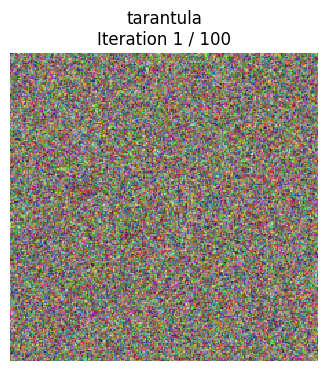

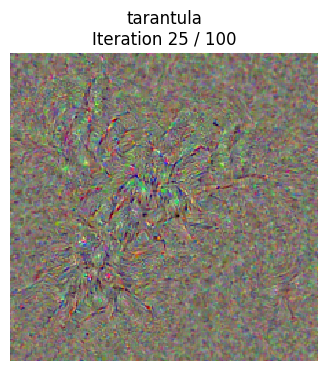

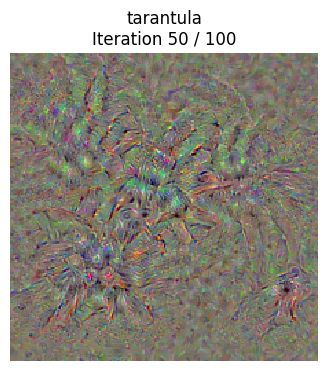

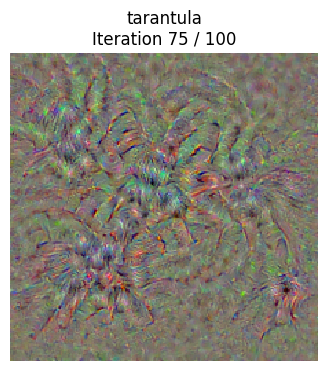

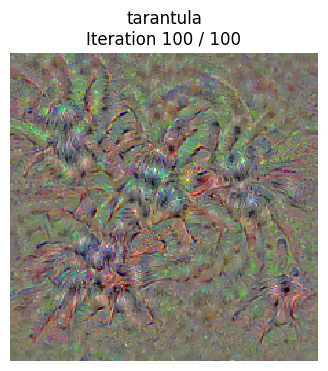

In [15]:
dtype = torch.FloatTensor
# dtype = torch.cuda.FloatTensor # Uncomment this to use GPU
model.type(dtype)

target_y = 76 # Tarantula
# target_y = 78 # Tick
# target_y = 187 # Yorkshire Terrier
# target_y = 683 # Oboe
# target_y = 366 # Gorilla
# target_y = 604 # Hourglass
out = create_class_visualization(target_y, model, dtype)

换一个目标类别，重复相同的优化过程，观察网络偏好的颜色和局部形状。

**第 16 块｜换一类检查生成模式**

在固定随机种子控制下选取另一类别，重复同一可视化流程。两次结果用于比较不同类别偏好的图像模式，不能只挑选最漂亮的结果而隐藏失败现象。

- `np.random.randint(1000)`：从给定整数范围抽样，结果用作索引或离散标签。

前序输入：`class_names` 来自第 5 块，`create_class_visualization` 来自第 14 块，`model` 来自第 4 块，`dtype` 来自第 15 块。

honeycomb


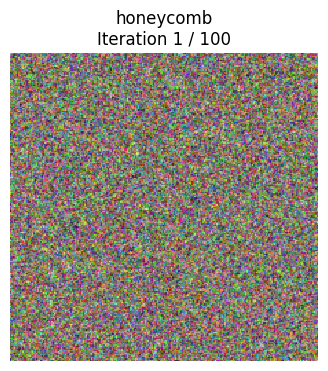

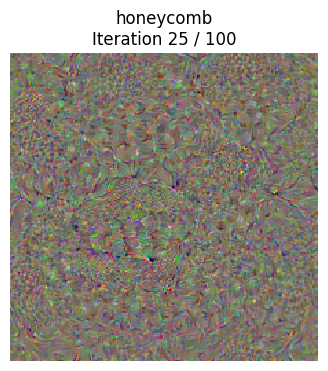

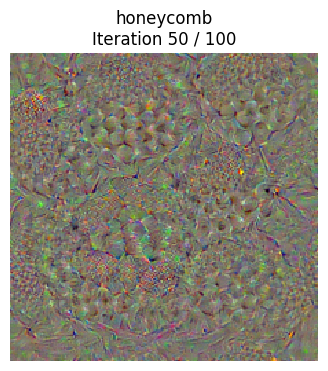

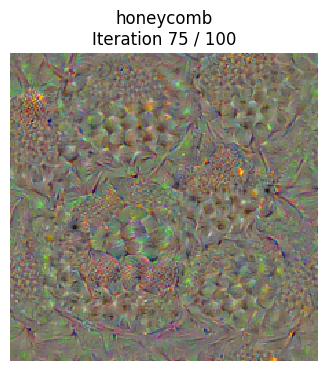

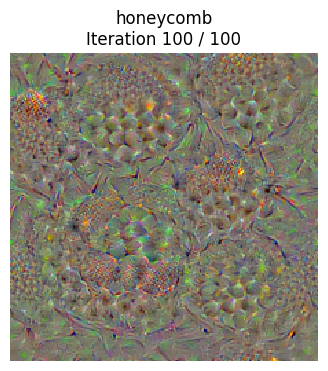

In [16]:
# target_y = 78 # Tick
# target_y = 187 # Yorkshire Terrier
# target_y = 683 # Oboe
# target_y = 366 # Gorilla
# target_y = 604 # Hourglass
target_y = np.random.randint(1000)
print(class_names[target_y])
X = create_class_visualization(target_y, model, dtype)

### 保存本次实验
输入是上面实际训练得到的模型、指标和曲线。只保存模型参数与实验结果，不复制原始数据；输出写入本题独立目录，供运行验证核对。

**第 17 块：顺着变量读**

本块实际导入：`study_runtime.save_experiment`。各模块在本题中的职责见开头的库说明。

In [17]:
from study_runtime import save_experiment
experiment_metrics = save_experiment(globals(), '013_NetworkVisualization_PyTorch')


本机实验指标： {}


## 实践补充：问题、检查与方法选择

**实际结果。** 目标类别欺骗图通过断言；显著图和类别可视化保存本机输出。长类别名已换行，避免标题重叠。

**已验证改进。** 方法二直接获取输入梯度，输出与方法一一致，并保留单图批次维度，不累积输入 .grad。

**解释边界。** 显著图描述局部梯度敏感性，不等于因果解释；可视化图像是优化出的网络偏好，不是真实类别样本。

更完整的故障证据见 [问题与解决记录](../003_问题与解决记录.md)。